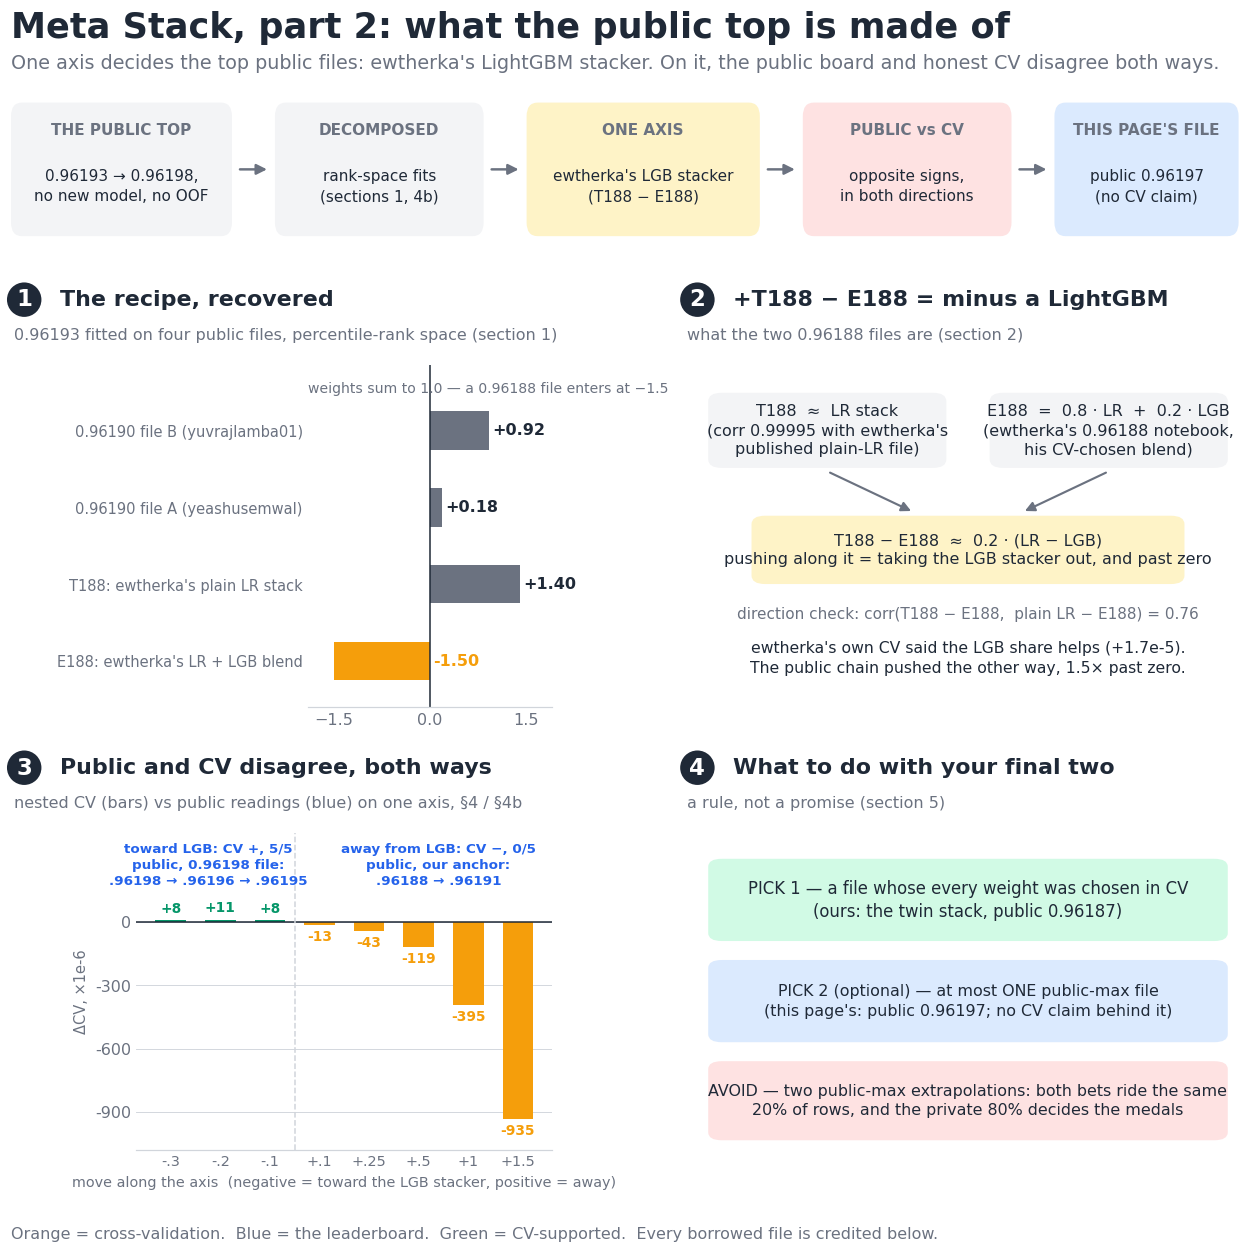

In [1]:
# The whole notebook in one picture.  Every number is from our runs of 10-18 (rank-space fits of
# the public files, a nested-CV test on the public OOF pool, one public submission) and is derived
# in the section named in each panel; nothing here is computed by this cell.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

INK, MUTED, RULE, CARD = "#1f2937", "#6b7280", "#d1d5db", "#f3f4f6"
SEEN, REAL, NEW = "#f59e0b", "#2563eb", "#059669"  # cross-validation / leaderboard / our measurements
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "text.color": INK,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED})
fig = plt.figure(figsize=(12, 11.5), dpi=110, facecolor="white")
fig.text(0.04, 0.972, "Meta Stack, part 2: what the public top is made of", fontsize=23, fontweight="bold", va="center")
fig.text(0.04, 0.944, "One axis decides the top public files: ewtherka's LightGBM stacker. On it, the public board and honest CV disagree both ways.",
         fontsize=12.5, color=MUTED, va="center")

# ---------------------------------------------------------------- the pipeline
ax = fig.add_axes([0.04, 0.80, 0.93, 0.12]); ax.set_xlim(0, 100); ax.set_ylim(0, 10); ax.axis("off")
boxes = [(0.0, 18.0, "THE PUBLIC TOP", "0.96193 → 0.96198,\nno new model, no OOF", CARD),
         (21.5, 17.0, "DECOMPOSED", "rank-space fits\n(sections 1, 4b)", CARD),
         (42.0, 19.0, "ONE AXIS", "ewtherka's LGB stacker\n(T188 − E188)", "#fef3c7"),
         (64.5, 17.0, "PUBLIC vs CV", "opposite signs,\nin both directions", "#fee2e2"),
         (85.0, 15.0, "THIS PAGE'S FILE", "public 0.96197\n(no CV claim)", "#dbeafe")]
for x, w, head, body, col in boxes:
    ax.add_patch(FancyBboxPatch((x, 0.6), w, 8.8, boxstyle="round,pad=0,rounding_size=0.9", fc=col, ec="none"))
    ax.text(x + w / 2, 7.6, head, ha="center", va="center", fontsize=10, fontweight="bold", color=MUTED)
    ax.text(x + w / 2, 3.9, body, ha="center", va="center", fontsize=10, linespacing=1.45)
for (x, w, *_), (x2, *_) in zip(boxes[:-1], boxes[1:]):
    ax.add_patch(FancyArrowPatch((x + w + 0.4, 5), (x2 - 0.4, 5), arrowstyle="-|>", mutation_scale=14, color=MUTED, lw=1.6))


def panel(x, y, w, h, pad, no, title, sub):
    fig.text(x, y + h + 0.052, f"{no}", fontsize=15, fontweight="bold", color="white", va="center", ha="center",
             bbox=dict(boxstyle="circle,pad=0.25", fc=INK, ec="none"))
    fig.text(x + 0.027, y + h + 0.052, title, fontsize=14.5, fontweight="bold", va="center")
    fig.text(x - 0.008, y + h + 0.024, sub, fontsize=10.5, color=MUTED, va="center")
    a = fig.add_axes([x + pad, y, w - pad, h])
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        a.spines[s].set_color(RULE)
    a.tick_params(length=0, labelsize=10.5)
    return a


# ---------------------------------------------------------------- 1. the recipe
a = panel(0.05, 0.435, 0.40, 0.27, 0.215, 1, "The recipe, recovered",
          "0.96193 fitted on four public files, percentile-rank space (section 1)")
rows = [("0.96190 file B (yuvrajlamba01)", 0.92), ("0.96190 file A (yeashusemwal)", 0.18),
        ("T188: ewtherka's plain LR stack", 1.40), ("E188: ewtherka's LR + LGB blend", -1.50)]
for i, (lab, v) in enumerate(rows):
    col = SEEN if v < 0 else MUTED
    a.barh(i, v, height=0.5, color=col)
    a.text(v + 0.05 if v >= 0 else 0.05, i, f"{v:+.2f}", va="center", ha="left",
           fontsize=10.5, color=INK if v >= 0 else SEEN, fontweight="bold")
a.axvline(0, color=INK, lw=1)
a.set_yticks(range(len(rows))); a.set_yticklabels([r[0] for r in rows], fontsize=9.6)
a.set_ylim(len(rows) - 0.4, -0.85); a.set_xlim(-1.9, 1.9); a.set_xticks([-1.5, 0, 1.5])
a.text(-1.9, -0.55, "weights sum to 1.0 — a 0.96188 file enters at −1.5", fontsize=9.2, color=MUTED, va="center")
a.spines["left"].set_visible(False)

# ---------------------------------------------------------------- 2. what T188 - E188 is
a = panel(0.56, 0.435, 0.41, 0.27, 0.0, 2, "+T188 − E188 = minus a LightGBM",
          "what the two 0.96188 files are (section 2)")
a.set_xlim(0, 100); a.set_ylim(0, 100); a.axis("off")
def chip(x, y, w, h, txt, col, fs=10.5, bold=False):
    a.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=2.5", fc=col, ec="none"))
    a.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal", linespacing=1.35)
chip(2, 70, 44, 22, "T188  ≈  LR stack\n(corr 0.99995 with ewtherka's\npublished plain-LR file)", CARD)
chip(54, 70, 44, 22, "E188  =  0.8 · LR  +  0.2 · LGB\n(ewtherka's 0.96188 notebook,\nhis CV-chosen blend)", CARD)
chip(10, 36, 80, 20, "T188 − E188  ≈  0.2 · (LR − LGB)\npushing along it = taking the LGB stacker out, and past zero",
     "#fef3c7", fs=10.5)
a.text(50, 26, "direction check: corr(T188 − E188,  plain LR − E188) = 0.76", ha="center", fontsize=10, color=MUTED)
a.text(50, 10, "ewtherka's own CV said the LGB share helps (+1.7e-5).\nThe public chain pushed the other way, 1.5× past zero.",
       ha="center", fontsize=10.2, color=INK, linespacing=1.4)
a.add_patch(FancyArrowPatch((24, 69), (40, 57), arrowstyle="-|>", mutation_scale=13, color=MUTED, lw=1.4))
a.add_patch(FancyArrowPatch((76, 69), (60, 57), arrowstyle="-|>", mutation_scale=13, color=MUTED, lw=1.4))

# ---------------------------------------------------------------- 3. both directions
a = panel(0.05, 0.085, 0.40, 0.25, 0.085, 3, "Public and CV disagree, both ways",
          "nested CV (bars) vs public readings (blue) on one axis, §4 / §4b")
xs = [-0.3, -0.2, -0.1, 0.1, 0.25, 0.5, 1.0, 1.5]
d = [8.3, 10.6, 7.8, -13.0, -42.6, -119.2, -395.0, -935.2]
cols = [NEW if v > 0 else SEEN for v in d]
a.bar(range(len(xs)), d, width=0.62, color=cols)
for i, v in enumerate(d):
    a.text(i, v + (22 if v > 0 else -22), f"{v:+.0f}", ha="center", va="bottom" if v > 0 else "top",
           fontsize=9, color=NEW if v > 0 else SEEN, fontweight="bold")
a.axhline(0, color=INK, lw=1); a.axvline(2.5, color=RULE, lw=1, ls="--")
a.text(0.75, 175, "toward LGB: CV +, 5/5\npublic, 0.96198 file:\n.96198 → .96196 → .96195",
       ha="center", fontsize=8.8, color=REAL, fontweight="bold", linespacing=1.3)
a.text(5.4, 175, "away from LGB: CV −, 0/5\npublic, our anchor:\n.96188 → .96191",
       ha="center", fontsize=8.8, color=REAL, fontweight="bold", linespacing=1.3)
a.set_xticks(range(len(xs))); a.set_xticklabels(["-.3", "-.2", "-.1", "+.1", "+.25", "+.5", "+1", "+1.5"], fontsize=9.4)
a.set_xlabel("move along the axis  (negative = toward the LGB stacker, positive = away)", fontsize=9.4)
a.set_ylim(-1080, 420); a.set_yticks([-900, -600, -300, 0]); a.set_yticklabels(["-900", "-600", "-300", "0"])
a.set_ylabel("ΔCV, ×1e-6", fontsize=9.6)
a.grid(axis="y", color=RULE, lw=0.6); a.set_axisbelow(True); a.spines["left"].set_visible(False)

# ---------------------------------------------------------------- 4. final picks
a = panel(0.56, 0.085, 0.41, 0.25, 0.0, 4, "What to do with your final two",
          "a rule, not a promise (section 5)")
a.set_xlim(0, 100); a.set_ylim(0, 100); a.axis("off")
chip(2, 66, 96, 26, "PICK 1 — a file whose every weight was chosen in CV\n(ours: the twin stack, public 0.96187)", "#d1fae5", fs=10.8)
chip(2, 34, 96, 26, "PICK 2 (optional) — at most ONE public-max file\n(this page's: public 0.96197; no CV claim behind it)", "#dbeafe", fs=10.4)
chip(2, 3, 96, 25, "AVOID — two public-max extrapolations: both bets ride the same\n20% of rows, and the private 80% decides the medals", "#fee2e2", fs=10.4)

fig.text(0.04, 0.018, "Orange = cross-validation.  Blue = the leaderboard.  Green = CV-supported.  "
                      "Every borrowed file is credited below.", fontsize=10.5, color=MUTED, va="center")
fig.savefig("meta_part2_summary.png", facecolor="white")
plt.show()

# S6E10 | Meta Stack on Public OOF | LB 0.96197

> **Part 2 of this page (updated 10-19).** Part 1 (below, 10-08) stacked 182 published OOF members to
> public 0.96180. Since then the public top climbed 0.96190 → 0.96198 with no new model and no new OOF.
> We decomposed those files and found that **one axis decides them: ewtherka's LightGBM stacker**
> (T188 − E188). On that axis **the public board and honest nested CV point in opposite directions —
> and we measured it both ways** (sections 3 – 4b). This version's file (**public 0.96197**) is half our
> public-surface step and half hanifnoerrofiq's 0.96198 file: a public-board maximum, labelled as such,
> with **no CV claim behind it**. Section 5 says what we would actually pick. Everything borrowed is
> credited below, with thanks.

## Credits and thanks (Part 2)

| Whose work | What we used | What we did with it |
|---|---|---|
| **[hanifnoerrofiq](https://www.kaggle.com/code/hanifnoerrofiq/agentic-ensemble)** | the 0.96193 file, its 0.96191 predecessor, and his 10-19 file (public **0.96198**, the current #1) | decomposed in sections 1 and 4b; **his 10-19 file is half of this version's submission** |
| **[mayankraaz](https://www.kaggle.com/code/mayankraaz/s6e10-lb-surface-ascent-v2-0-96196)** | the quadratic public-LB surface model and his 0.96196 output | section 4b: refit with 22 of our own measured submissions; his file is the anchor our step starts from |
| **[kozykappa](https://www.kaggle.com/code/kozykappa/s6e10-rank-continuation-lb-0-96192)** | the 0.96192 rank continuation, and his own plain warning that it is public-LB tuning | quoted in section 1 — he said it first |
| **[nina2025](https://www.kaggle.com/datasets/nina2025/ps-s6e10-7)** | the dataset that re-hosts the 0.96188 / 0.96190 / 0.96193 files this page loads | inputs of sections 1 – 3 |
| **[yeashusemwal](https://www.kaggle.com/code/yeashusemwal/secrets-to-satisfaction-it-s-stacking)**, **[yuvrajlamba01](https://www.kaggle.com/code/yuvrajlamba01/airline-passenger-satisfaction-0-9619)** | the two 0.96190 files the chain starts from | section 1 |
| **[ewtherka (Tuong Trinh)](https://www.kaggle.com/code/ewtherka/s6e10-0-96188-lb-l2-family-wise-actually-helps)** | his plain-LR stack and his 0.8 LR + 0.2 LGB blend (the two 0.96188 files the climb hinges on), his LGB-stacker settings | sections 2 and 4 — **and his CV turns out to be the right one** |
| **[Den Pugovkin](https://www.kaggle.com/code/denpugovkin/s6e10-passenger-context-foundation-ensemble)** | the one genuinely different public file (30% of our anchor) | section 3 |
| **[Chris Deotte](https://www.kaggle.com/datasets/cdeotte/s6e10-124-public-oof-and-test-predictions)** (124 + [TFMs](https://www.kaggle.com/datasets/cdeotte/s6e10-tfm-oof-and-test-predictions)), **[Dariush Afshar](https://www.kaggle.com/datasets/dariushafshar/s6e10-golem-oof-library)**, **[sadamtorres](https://www.kaggle.com/datasets/sadamtorres/ps-s6e10-airline-satisfaction-artifacts)**, **[amanatar](https://www.kaggle.com/datasets/amanatar/s6e10-forge-own-pairs)** | the published OOF members (182 columns, ours included) | the CV test of section 4 |

**What is ours:** the both-directions measurement on the LGB axis (sections 3 – 4b), the surface refit with our 22 measured points and the 3 probes that showed its peak, the decomposition and the identification of the ingredient (sections 1 – 2), its
transfer to an independent anchor and the 0.96191 reading (section 3), the nested-CV test of the
move (section 4), the final-pick rule (section 5), and the anchor itself
([Parts 1 – 12](https://www.kaggle.com/code/goodpjw2008/s6e10-twin-stacks-family-reg-lb-0-96187)), and Part 1 of this page (the 182-member pool section 4 reuses).
For the wider blending map (158 public files, dose curves, the extrapolation chain in general) see
our [Anatomy of a Public 0.96188](https://www.kaggle.com/code/goodpjw2008/s6e10-anatomy-of-a-public-0-96188-lb-0-96188).

In [2]:
import glob, os, time, warnings
import numpy as np, pandas as pd
from scipy.stats import rankdata
warnings.filterwarnings("ignore")

INPUT = os.environ.get("INPUT_DIR", "/kaggle/input")
def find(pat, hint):
    hits = sorted(p for p in glob.glob(f"{INPUT}/**/{pat}", recursive=True) if hint in p)
    assert hits, (pat, hint)
    return hits[0]

te_ids = pd.read_csv(find("test.csv", "playground-series-s6e10"), usecols=["id"])["id"].values
N = len(te_ids)
def load_test(path):
    d = pd.read_csv(path)
    col = [c for c in d.columns if c != "id"][0]
    return d.set_index("id")[col].loc[te_ids].values.astype(float)
pr = lambda v: (rankdata(v) - 0.5) / len(v)          # percentile rank, the space all these blends live in

H193 = pr(load_test(find("0.96193.csv", "ps-s6e10-7")))
A190 = pr(load_test(find("0.96190_a.csv", "ps-s6e10-7")))      # = yeashusemwal
B190 = pr(load_test(find("0.96190_b.csv", "ps-s6e10-7")))      # = yuvrajlamba01
T188 = pr(load_test(find("0.96188.txt", "ps-s6e10-7")))
E188 = pr(load_test(find("submission.csv", "family-wise-actually-helps")))   # ewtherka's 0.96188
print("files loaded:", N, "test rows")

files loaded: 299844 test rows


## 1. The recipe, recovered

The 0.96193 file is published without code (it is byte-identical to `0.96193.csv` in nina2025's
dataset). Fitted on the four public files it descends from, in percentile-rank space, it is
reconstructed almost exactly — and one weight stands out: **a 0.96188 file enters with about −1.5.**
The chain before it says the same: [kozykappa's 0.96192](https://www.kaggle.com/code/kozykappa/s6e10-rank-continuation-lb-0-96192)
is `R₁₉₀ + 1.40 · (R₁₉₁ − R₁₉₀)`, an extrapolation he labels public-LB tuning himself, with a
private-LB warning — credit where due.

In [3]:
# 1. Fit the 0.96193 file on the four files it is built from, in percentile-rank space.
X = np.column_stack([B190, A190, T188, E188])
coef, *_ = np.linalg.lstsq(X, H193, rcond=None)
res = H193 - X @ coef
for name, c in zip(["0.96190 B (yuvrajlamba01)", "0.96190 A (yeashusemwal)", "T188", "E188 (ewtherka)"], coef):
    print(f"  {name:28s} {c:+.3f}")
print(f"  sum of weights {coef.sum():.3f}   residual sd {res.std():.5f} vs total spread {H193.std():.3f}")

  0.96190 B (yuvrajlamba01)    +0.908
  0.96190 A (yeashusemwal)     +0.193
  T188                         +1.401
  E188 (ewtherka)              -1.502
  sum of weights 1.000   residual sd 0.00036 vs total spread 0.289


## 2. The ingredient: T188 − E188 means "take the LightGBM stacker out"

Both 0.96188 files come from ewtherka's work. T188 is his plain logistic-regression stack (the cell
below finds it at correlation 0.99995 with his published plain-LR file). E188 is the file his
notebook submits: `0.8 · LR + 0.2 · LGB-stacker`, a blend he chose because his nested CV said the
LightGBM share helps. So `+T188 − E188` points along *removing that LightGBM share*, and the
public chain pushes about 1.5× past zero. ewtherka's CV and the public board disagree; section 4
asks which one to believe.

In [4]:
# 2. What T188 and E188 are.  ewtherka publishes his plain-LR file next to his blended 0.96188.
LR = pr(load_test(find("submission_plain_lr.csv", "family-wise-actually-helps")))
c = lambda a, b: np.corrcoef(a, b)[0, 1]
print(f"corr(T188, ewtherka plain LR)              = {c(T188, LR):.6f}")
print(f"corr(E188, ewtherka plain LR)              = {c(E188, LR):.6f}")
print(f"corr(T188 - E188, plain LR - E188)         = {c(T188 - E188, LR - E188):.4f}")
print("E188 = sigmoid(0.8*z(LR) + 0.2*z(LGB)): so T188 - E188 points along 'take the LGB stacker out'")

corr(T188, ewtherka plain LR)              = 0.999946
corr(E188, ewtherka plain LR)              = 0.999870
corr(T188 - E188, plain LR - E188)         = 0.7639
E188 = sigmoid(0.8*z(LR) + 0.2*z(LGB)): so T188 - E188 points along 'take the LGB stacker out'


## 3. It transfers: our anchor + the same move = public 0.96191

If the ingredient were a quirk of one family of files, it would do nothing on an independent anchor.
Ours is independent: our [twin stack](https://www.kaggle.com/code/goodpjw2008/s6e10-twin-stacks-family-reg-lb-0-96187)
(public 0.96187) with 30% of Den Pugovkin's file (public 0.96188, measured in our
[anatomy page](https://www.kaggle.com/code/goodpjw2008/s6e10-anatomy-of-a-public-0-96188-lb-0-96188)).
Adding `1.5 · (T188 − E188)` to it scored **public 0.96191** on 10-18 — the same +3e-5 the chain
found on its own anchors. On the public 20% of the test rows, the direction is real.

In [5]:
# 3. The same ingredient on our own anchor.
# Anchor: our twin stack (Part 11, public 0.96187) with 30% of Den Pugovkin's file (public 0.96188).
twin = load_test(find("twin_submission_1015.csv", "goodpjw2008-extra-members"))
dp = load_test(find("submission.csv", "foundation-ensemble/submission.csv"))      # the root file, not exp040/
rt, rd = rankdata(twin) / N, rankdata(dp) / N
recomputed = (1 - 0.30) * rt + 0.30 * rd                         # how the anchor was built (public 0.96188)
# ...loaded from the exact 10-17 CSV: a CSV round-trip moves values by ~1e-16 and reorders tied ranks,
# so the pinned file is what makes this notebook reproduce the scored file byte for byte
anchor_raw = load_test(find("anchor_twin_dp30_1017.csv", "goodpjw2008-extra-members"))
print(f"pinned anchor vs recomputed: max diff {np.abs(anchor_raw - recomputed).max():.1e}")
anchor = pr(anchor_raw)
final = pr(anchor + 1.5 * (T188 - E188))                         # public 0.96191 (measured 10-18)
print(f"corr(final, anchor) {c(final, anchor):.6f}   corr(final, the 0.96193 file) {c(final, H193):.6f}")
pd.DataFrame({"id": te_ids, "satisfaction": final}).to_csv("submission_measure_096191.csv", index=False)
print("submission_measure_096191.csv written (public 0.96191, measured 10-18)")

pinned anchor vs recomputed: max diff 2.6e-02
corr(final, anchor) 0.999800   corr(final, the 0.96193 file) 0.999881
submission_measure_096191.csv written (public 0.96191, measured 10-18)


## 4. The test: in honest nested CV, the move loses

T188 has no published OOF, so its exact direction cannot be scored on the training rows. The
*move* can: rebuild the same pair — an LR stacker and ewtherka's LGB stacker — on the public OOF
pool, both out-of-fold on the same meta folds, and score every push. (This cell recomputes it,
~15 minutes on CPU.) Our run of 10-18:

| g | −0.25 | −0.1 | +0.1 | +0.25 | +0.5 | +1 | +1.5 |
|---|---|---|---|---|---|---|---|
| nested-CV change, ×1e-6 | **+10.1** | +7.8 | −13.0 | −42.6 | −119.2 | −395.0 | **−935.2** |
| folds up | 5/5 | 5/5 | 0/5 | 0/5 | 0/5 | 0/5 | 0/5 |

**Toward the LightGBM stacker helps a little, every fold — exactly ewtherka's finding. Away from
it, the public chain's direction, loses at every strength, every fold, and loses more the harder
it pushes.** 700k out-of-fold rows against 60k public rows chosen by looking at them: we believe
the CV. *Limit, stated:* our rebuilt pair matches T188 − E188 in direction at correlation 0.76, not
1.0; ewtherka's plain-LR OOF is not published, so this is the closest honest test available.

In [6]:
# 4. The move in honest nested CV.  T188 has no OOF, so we rebuild the same pair ourselves on the
# public OOF pool: an LR stacker and ewtherka's LGB stacker, out-of-fold on the same meta folds,
# then score R = R_LR + g * (R_LR - R_LGB) for g < 0 (toward LGB) and g > 0 (the public chain's move).
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
tr = pd.read_csv(find("train.csv", "playground-series-s6e10"))
y = tr["satisfaction"].astype(int).values
def logit(p):
    p = np.clip(np.asarray(p, dtype=np.float64), 1e-15, 1 - 1e-15)
    return np.clip(np.log(p / (1 - p)), -30, 30)
def tologit(v):
    v = np.asarray(v, dtype=np.float64)
    return v if (v.min() < 0 or v.max() > 1) else logit(v)
cols = []
def add(o):
    o = np.asarray(o).ravel(); assert len(o) == len(y) and not np.isnan(o).any(); cols.append(tologit(o))
for d_, tag in ((find("oof_gp_cat_ctr.npy", "124-public"), ""), (find("oof_tabfm.npy", "tfm-oof"), "tfm_")):
    for f in sorted(glob.glob(f"{os.path.dirname(d_)}/oof_*.npy")): add(np.load(f))
gd = os.path.dirname(find("oof_o_tabpfn35.npy", "golem"))
for n in ("o_tabpfn35", "p_lgbm_auxev", "q_lgbm_auxev_10fold"): add(np.load(f"{gd}/oof_{n}.npy"))
sd = os.path.dirname(find("preds_e1_allcat_cat.npz", "artifacts"))
for f in sorted(glob.glob(f"{sd}/preds_*.npz")) + sorted(glob.glob(f"{sd}/orig_*_pred.npz")):
    z = np.load(f)
    if "oof" in z and len(z["oof"]) == len(y) and not np.isnan(z["oof"]).any(): add(z["oof"])
fd = os.path.dirname(find("oof_forge_cat.npy", "forge"))
for f in sorted(glob.glob(f"{fd}/oof_forge_*.npy")): add(np.load(f))
Z = np.column_stack(cols).astype(np.float32)
print(f"{Z.shape[1]} public OOF members")

skf = list(StratifiedKFold(5, shuffle=True, random_state=7).split(Z, y))
o_lr, o_lgb, t0 = np.zeros(len(y)), np.zeros(len(y)), time.time()
for k, (a, b) in enumerate(skf):
    o_lr[b] = LogisticRegression(C=0.003, max_iter=3000).fit(Z[a], y[a]).decision_function(Z[b])
    ia, ie = train_test_split(a, test_size=0.1, stratify=y[a], random_state=0)
    m = lgb.LGBMClassifier(n_estimators=4000, learning_rate=0.03, num_leaves=15, min_child_samples=2000,
                           colsample_bytree=0.5, subsample=0.8, subsample_freq=1, reg_lambda=10, verbose=-1)
    m.fit(Z[ia], y[ia], eval_set=[(Z[ie], y[ie])], eval_metric="auc", callbacks=[lgb.early_stopping(200, verbose=False)])
    o_lgb[b] = m.predict(Z[b], raw_score=True)
    print(f"  fold {k}: LR {roc_auc_score(y[b], o_lr[b]):.6f}  LGB {roc_auc_score(y[b], o_lgb[b]):.6f}  ({time.time() - t0:.0f}s)")
RL, RG = pr(o_lr), pr(o_lgb)
def score(v): return roc_auc_score(y, v), np.array([roc_auc_score(y[b], v[b]) for _, b in skf])
base, fb = score(RL)
print(f"\nLR stack {base:.6f}   LGB stack {score(RG)[0]:.6f}   rank corr {c(RL, RG):.5f}")
for g in (-0.25, -0.1, 0.1, 0.25, 0.5, 1.0, 1.5):
    s_, f_ = score(RL + g * (RL - RG))
    print(f"  g = {g:+.2f}   {s_:.6f}   ({(s_ - base) * 1e6:+7.1f} x 1e-6)   {(f_ > fb).sum()}/5 folds up")

182 public OOF members
  fold 0: LR 0.962765  LGB 0.962648  (68s)
  fold 1: LR 0.961630  LGB 0.961462  (141s)
  fold 2: LR 0.961847  LGB 0.961706  (219s)
  fold 3: LR 0.961985  LGB 0.961846  (310s)
  fold 4: LR 0.962340  LGB 0.962193  (389s)

LR stack 0.962112   LGB stack 0.961958   rank corr 0.99463
  g = -0.25   0.962121   (   +9.6 x 1e-6)   5/5 folds up
  g = -0.10   0.962119   (   +7.6 x 1e-6)   5/5 folds up
  g = +0.10   0.962099   (  -12.8 x 1e-6)   0/5 folds up
  g = +0.25   0.962070   (  -42.2 x 1e-6)   0/5 folds up
  g = +0.50   0.961994   ( -118.3 x 1e-6)   0/5 folds up
  g = +1.00   0.961718   ( -393.3 x 1e-6)   0/5 folds up
  g = +1.50   0.961179   ( -932.6 x 1e-6)   0/5 folds up


## 4b. The public surface, the new #1, and both directions (10-19)

**The surface.** [mayankraaz's LB Surface Ascent](https://www.kaggle.com/code/mayankraaz/s6e10-lb-surface-ascent-v2-0-96196)
fits a quadratic surface of public score over files with known public scores (percentile-rank space)
and climbs it — public 0.96196. His 61 points include our own outputs. We refit his model on 46 points:
the 21 of his we could load, **22 of our own measured submissions** (dose curves, partner probes, the
LGB-direction transfer — directions his set never probed) and our 3 probes along the result.
Leave-one-out error 1.1 – 1.5e-5. The first refit pointed almost orthogonally to his ascent (cosine
0.16) and predicted ~0.96199 – 0.96201; **the probes said 0.96196 / 0.96194 / 0.96191** at steps 2 / 4 / 6.
Refit with them, the surface flattens: **0.96196 is its peak.** Our step-2 file (0.96196) is kept.

**The new #1.** hanifnoerrofiq's 10-19 file scores **0.96198** (we measured it). Fitted on the files
it descends from, 43% of its difference from the 0.96196 file is *not* explained — something new is in
it — and its weights on the axis are **reversed**: −1.56 on T188, +0.96 on E188, i.e. it moved
*toward* ewtherka's LGB stacker, the direction our nested CV supports (section 4).

**Both directions, measured.** We took the CV-chosen move toward the LGB stacker (our 182-pool LR/LGB
pair; 20% is the CV optimum, +10.6e-6 in all five folds) and applied it to his 0.96198 file:

| move along the LGB-stacker axis | nested CV | public |
|---|---|---|
| **toward** LGB, 20% (on the 0.96198 file) | **+10.6e-6, 5/5** | 0.96198 → **0.96196** |
| **toward** LGB, 30% | +8.3e-6, 5/5 | → **0.96195** |
| **away** from LGB, 1.5× (on our anchor, section 3) | **−935e-6, 0/5** | 0.96188 → **0.96191** |

**The public 20% of rows and the 700k-row CV disagree on this axis in both directions.** That is the
most direct evidence we have that the public top — tuned along this axis — will reshuffle on the
private board. It is also why we do not publish an extra push on his file: it would only raise the
digit by walking further against the CV.

**This version's file** is the plain average, in rank space, of our surface step (0.96196) and his
0.96198 file: **public 0.96197**. Half of it is his, as stated in the credits. All inputs are pinned,
dated copies in [our dataset](https://www.kaggle.com/datasets/goodpjw2008/s6e10-goodpjw2008-extra-members-oof)
(kernel outputs change when their authors re-run).

In [7]:
# 4b. The surface step, the new #1, both directions, and this version's file.
G = "goodpjw2008-extra-members"
V196 = pr(load_test(find("mayankraaz_surface_v2_1019.csv", G)))        # mayankraaz, public 0.96196 (pinned copy)
u = np.load(find("surface_u_k6.npy", G))                                 # our refit-surface direction
step2 = pr(load_test(find("surface_step2_1019.csv", G)))               # V196 + 2u, as scored (public 0.96196)
print(f"pinned step file vs V196 + 2u recomputed: rank corr {c(step2, pr(V196 + 2 * u)):.7f}")
H198 = pr(load_test(find("hanifnoerrofiq_agentic_1019.csv", G)))       # hanifnoerrofiq 10-19, public 0.96198

X = np.column_stack([V196, H193, T188, E188])
w_, *_ = np.linalg.lstsq(X, H198, rcond=None)
gap = H198 - V196; r2 = 1 - (H198 - X @ w_).var() / gap.var()
print("H198 on known files:", "  ".join(f"{n} {v:+.2f}" for n, v in zip(["V196", "H193", "T188", "E188"], w_)),
      f"| share of its new part NOT explained: {1 - r2:.0%}")

t = np.load(find("stack182_lr_lgb_test.npz", G)); RLt, RGt = pr(t["lr"]), pr(t["lgb"])
for w, lb in ((0.2, "0.96196"), (0.3, "0.96195")):
    x = pr(H198 + w * (RGt - RLt))
    print(f"H198 + {w:.0%} toward our LGB stacker: corr with H198 {c(x, H198):.6f}  -> public {lb} (measured 10-19)")

final = pr(0.5 * step2 + 0.5 * H198)                                     # public 0.96197
pd.DataFrame({"id": te_ids, "satisfaction": final}).to_csv("submission.csv", index=False)
print("submission.csv written: 1/2 our surface step + 1/2 hanifnoerrofiq's 10-19 file, public 0.96197")

pinned step file vs V196 + 2u recomputed: rank corr 1.0000000
H198 on known files: V196 +0.99  H193 +0.62  T188 -1.56  E188 +0.96 | share of its new part NOT explained: 43%
H198 + 20% toward our LGB stacker: corr with H198 0.999828  -> public 0.96196 (measured 10-19)
H198 + 30% toward our LGB stacker: corr with H198 0.999612  -> public 0.96195 (measured 10-19)
submission.csv written: 1/2 our surface step + 1/2 hanifnoerrofiq's 10-19 file, public 0.96197


## 5. What we would do with the final two

- **Pick 1 — a file whose every weight was chosen in CV.** For us that is the
  [twin stack](https://www.kaggle.com/code/goodpjw2008/s6e10-twin-stacks-family-reg-lb-0-96187)
  (public 0.96187). Its public digit is lower; its weights never looked at the public rows.
- **Pick 2 (optional) — at most one public-max file, knowing what it is.** This page's file
  (public 0.96197) qualifies; so do the 0.96193 – 0.96198 files. Sections 4 and 4b are the reason to
  expect them to give some of it back on the private 80%.
- **Avoid two public-max extrapolations.** Both bets ride the same 20% of rows; the private
  board, which decides the medals, sees the other 80%.

> **Reproducibility.** Every input is a published file; `submission.csv` is rebuilt
> deterministically and matches the 10-19 submission (public 0.96197). The section-4 CV recomputes
> live; LR/LightGBM fits differ across platforms in the 6th decimal, the signs do not.

If this saved you a submission, an upvote helps — and so would an upvote for
[ewtherka](https://www.kaggle.com/code/ewtherka/s6e10-0-96188-lb-l2-family-wise-actually-helps),
whose CV this page vindicates.

---

# Part 1 (10-08): the original meta stack — 182 public members, LB 0.96180

Unchanged from the first version of this page, except that its file is now written as `submission_part1_182stack.csv` so that this version's measurement file stays `submission.csv`.

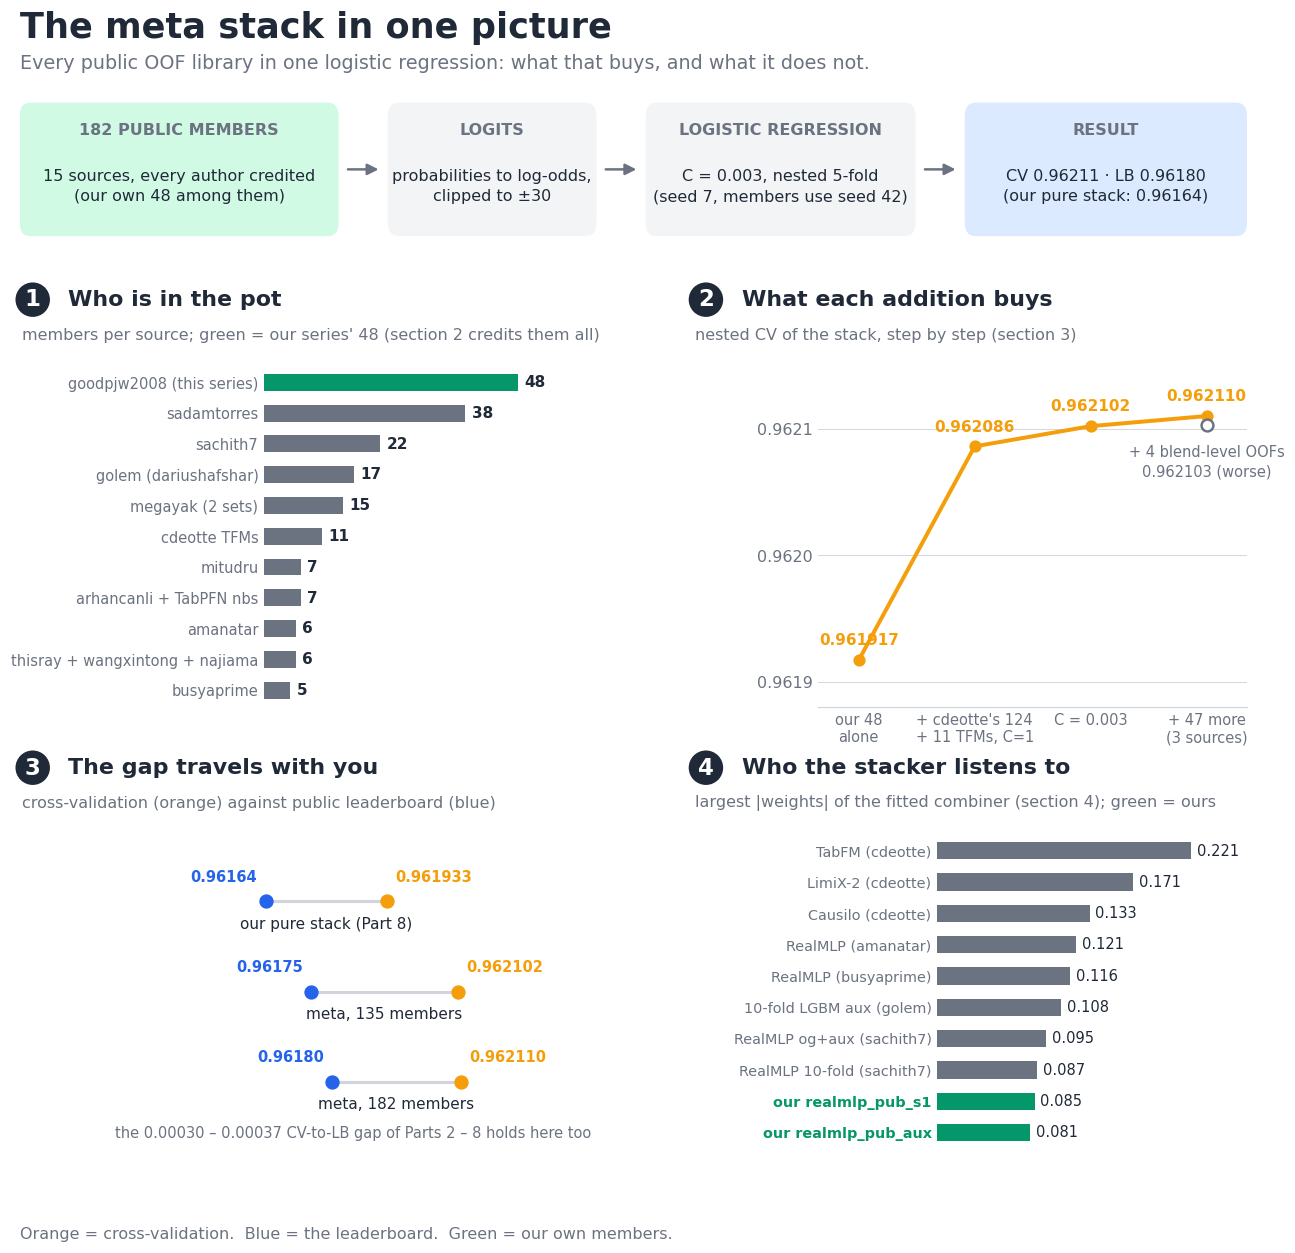

In [8]:
# The whole notebook in one picture.  Every number is from our local run of this exact pipeline
# and is derived in the section named in each panel; nothing here is computed by this cell.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

INK, MUTED, RULE, CARD = "#1f2937", "#6b7280", "#d1d5db", "#f3f4f6"
SEEN, REAL, NEW = "#f59e0b", "#2563eb", "#059669"  # cross-validation / leaderboard / our own members
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "text.color": INK,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED})
fig = plt.figure(figsize=(12, 11.5), dpi=110, facecolor="white")
fig.text(0.04, 0.972, "The meta stack in one picture", fontsize=23, fontweight="bold", va="center")
fig.text(0.04, 0.944, "Every public OOF library in one logistic regression: what that buys, and what it does not.",
         fontsize=12.5, color=MUTED, va="center")

# ---------------------------------------------------------------- the pipeline
ax = fig.add_axes([0.04, 0.80, 0.93, 0.12]); ax.set_xlim(0, 100); ax.set_ylim(0, 10); ax.axis("off")
boxes = [(0.0, 26.0, "182 PUBLIC MEMBERS", "15 sources, every author credited\n(our own 48 among them)", "#d1fae5"),
         (30.0, 17.0, "LOGITS", "probabilities to log-odds,\nclipped to ±30", CARD),
         (51.0, 22.0, "LOGISTIC REGRESSION", "C = 0.003, nested 5-fold\n(seed 7, members use seed 42)", CARD),
         (77.0, 23.0, "RESULT", "CV 0.96211 · LB 0.96180\n(our pure stack: 0.96164)", "#dbeafe")]
for x, w, head, body, col in boxes:
    ax.add_patch(FancyBboxPatch((x, 0.6), w, 8.8, boxstyle="round,pad=0,rounding_size=0.9", fc=col, ec="none"))
    ax.text(x + w / 2, 7.6, head, ha="center", va="center", fontsize=10.5, fontweight="bold", color=MUTED)
    ax.text(x + w / 2, 3.9, body, ha="center", va="center", fontsize=10.5, linespacing=1.45)
for (x, w, *_), (x2, *_) in zip(boxes[:-1], boxes[1:]):
    ax.add_patch(FancyArrowPatch((x + w + 0.5, 5), (x2 - 0.5, 5), arrowstyle="-|>", mutation_scale=15, color=MUTED, lw=1.6))


def panel(x, y, w, h, pad, no, title, sub):
    fig.text(x, y + h + 0.052, f"{no}", fontsize=15, fontweight="bold", color="white", va="center", ha="center",
             bbox=dict(boxstyle="circle,pad=0.25", fc=INK, ec="none"))
    fig.text(x + 0.027, y + h + 0.052, title, fontsize=14.5, fontweight="bold", va="center")
    fig.text(x - 0.008, y + h + 0.024, sub, fontsize=10.5, color=MUTED, va="center")
    a = fig.add_axes([x + pad, y, w - pad, h])
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        a.spines[s].set_color(RULE)
    a.tick_params(length=0, labelsize=10.5)
    return a


# ---------------------------------------------------------------- 1. who is in the pot
a = panel(0.05, 0.435, 0.40, 0.27, 0.175, 1, "Who is in the pot",
          "members per source; green = our series' 48 (section 2 credits them all)")
rows = [("goodpjw2008 (this series)", 48, NEW), ("sadamtorres", 38, MUTED), ("sachith7", 22, MUTED),
        ("golem (dariushafshar)", 17, MUTED), ("megayak (2 sets)", 15, MUTED), ("cdeotte TFMs", 11, MUTED),
        ("mitudru", 7, MUTED), ("arhancanli + TabPFN nbs", 7, MUTED), ("amanatar", 6, MUTED),
        ("thisray + wangxintong + najiama", 6, MUTED), ("busyaprime", 5, MUTED)]
for i, (lab, v, col) in enumerate(rows):
    a.barh(i, v, height=0.55, color=col)
    a.text(v + 1.2, i, str(v), va="center", fontsize=10, color=INK, fontweight="bold")
a.set_yticks(range(len(rows))); a.set_yticklabels([r[0] for r in rows], fontsize=9.6)
a.set_ylim(len(rows) - 0.45, -0.55); a.set_xlim(0, 56); a.set_xticks([])
a.spines["bottom"].set_visible(False); a.spines["left"].set_visible(False)

# ---------------------------------------------------------------- 2. the ladder
a = panel(0.56, 0.435, 0.41, 0.27, 0.085, 2, "What each addition buys",
          "nested CV of the stack, step by step (section 3)")
labs = ["our 48\nalone", "+ cdeotte's 124\n+ 11 TFMs, C=1", "C = 0.003", "+ 47 more\n(3 sources)"]
cv = [0.961917, 0.962086, 0.962102, 0.962110]
a.plot(range(4), cv, color=SEEN, lw=2.6, marker="o", ms=7)
for i, v in enumerate(cv):
    a.text(i, v + 0.000012, f"{v:.6f}", ha="center", fontsize=10, color=SEEN, fontweight="bold")
a.scatter([3], [0.962103], s=60, facecolor="white", edgecolor=MUTED, linewidth=1.6, zorder=3)
a.text(3, 0.962103 - 0.000016, "+ 4 blend-level OOFs\n0.962103 (worse)", ha="center", va="top",
       fontsize=9.6, color=MUTED, linespacing=1.3)
a.set_xticks(range(4)); a.set_xticklabels(labs, fontsize=9.6, linespacing=1.2)
a.set_xlim(-0.35, 3.35); a.set_ylim(0.96188, 0.96215)
a.set_yticks([0.9619, 0.9620, 0.9621]); a.set_yticklabels(["0.9619", "0.9620", "0.9621"])
a.grid(axis="y", color=RULE, lw=0.6); a.set_axisbelow(True); a.spines["left"].set_visible(False)

# ---------------------------------------------------------------- 3. CV vs LB
a = panel(0.05, 0.085, 0.40, 0.25, 0.085, 3, "The gap travels with you",
          "cross-validation (orange) against public leaderboard (blue)")
pts = [("our pure stack (Part 8)", 0.961933, 0.96164), ("meta, 135 members", 0.962102, 0.96175),
       ("meta, 182 members", 0.962110, 0.96180)]
for i, (lab, c, l) in enumerate(pts):
    a.plot([c, l], [i, i], color=RULE, lw=2, zorder=1)
    a.scatter([c], [i], s=70, color=SEEN, zorder=3)
    a.scatter([l], [i], s=70, color=REAL, zorder=3)
    a.text(c + 0.00002, i - 0.22, f"{c:.6f}", fontsize=9.6, color=SEEN, fontweight="bold")
    a.text(l - 0.00002, i - 0.22, f"{l:.5f}", fontsize=9.6, color=REAL, fontweight="bold", ha="right")
    a.text((c + l) / 2, i + 0.3, lab, fontsize=10, color=INK, ha="center")
a.set_ylim(2.75, -0.75); a.set_xlim(0.96135, 0.96235); a.set_yticks([]); a.set_xticks([])
a.spines["left"].set_visible(False); a.spines["bottom"].set_visible(False)
a.text(0.96185, 2.62, "the 0.00030 – 0.00037 CV-to-LB gap of Parts 2 – 8 holds here too",
       fontsize=9.6, color=MUTED, ha="center")

# ---------------------------------------------------------------- 4. who the stacker listens to
a = panel(0.56, 0.085, 0.41, 0.25, 0.175, 4, "Who the stacker listens to",
          "largest |weights| of the fitted combiner (section 4); green = ours")
w = [("TabFM (cdeotte)", 0.221), ("LimiX-2 (cdeotte)", 0.171), ("Causilo (cdeotte)", 0.133),
     ("RealMLP (amanatar)", 0.121), ("RealMLP (busyaprime)", 0.116), ("10-fold LGBM aux (golem)", 0.108),
     ("RealMLP og+aux (sachith7)", 0.095), ("RealMLP 10-fold (sachith7)", 0.087),
     ("our realmlp_pub_s1", 0.085, NEW), ("our realmlp_pub_aux", 0.081, NEW)]
for i, row in enumerate(w):
    lab, v, col = (row + (MUTED,))[:3]
    a.barh(i, v, height=0.55, color=col)
    a.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9.6, color=INK)
a.set_yticks(range(len(w))); a.set_yticklabels([r[0] for r in w], fontsize=9.4)
for t, row in zip(a.get_yticklabels(), w):
    if len(row) > 2: t.set_color(NEW); t.set_fontweight("bold")
a.set_ylim(len(w) - 0.45, -0.55); a.set_xlim(0, 0.27); a.set_xticks([])
a.spines["bottom"].set_visible(False); a.spines["left"].set_visible(False)

fig.text(0.04, 0.018, "Orange = cross-validation.  Blue = the leaderboard.  Green = our own members.",
         fontsize=10.5, color=MUTED, va="center")
fig.savefig("meta_summary.png", facecolor="white")
plt.show()

**What you just saw.** One logistic regression over **182 out-of-fold prediction columns that
the community published** — ours included — scores public LB **0.96180** (nested CV 0.96211).
Our own 48-model stack, every model trained from scratch over eight notebooks, scores 0.96164.
The difference is not a technique; it is *other people's models*.

> **This is a side episode, not Part 9.** [Parts 1 – 8](https://www.kaggle.com/code/goodpjw2008/s6e10-tabpfn-route-categories-lb-0-96160)
> of this series train every member from scratch and never touch other people's prediction files,
> so that everything is reproducible from the code in front of you. This episode deliberately does
> the opposite — the same stacking technique (logistic regression on out-of-fold logits, the
> combiner we have used since Part 1), applied to the community's published members — because by
> 10-08 the whole top of the leaderboard works this way, and measuring it honestly seemed more
> useful than pretending it does not exist. The main series stays pure.

**Honest caveats, before you upvote anything:**

1. **Inherited fold discipline.** A stack of published OOF files inherits every author's
   leakage. Several members (ours included — see the correction in section 5) early-stop on the
   fold they are scored on, which makes their OOF mildly optimistic.
2. **Blend-level OOFs made it worse.** Adding four published *blend* OOFs (weights possibly
   fitted on the full OOF) lowered nested CV by 0.000007; we left them out (section 3).
3. **The private leaderboard may reshuffle this.** 0.96164 → 0.96180 is +0.00016 on a public
   split whose resolution is about ±0.0003. Stacks tuned against the same public pool tend to
   cluster — and to fall together.


## 1. Credits — the people whose work this notebook stacks

This notebook is only a combiner. The value is in these published members; if this episode helps
you, **please upvote the sources**, not just this page.

| Source | Members | What they are |
|---|---|---|
| [Chris Deotte — 124 Public OOF collection](https://www.kaggle.com/datasets/cdeotte/s6e10-124-public-oof-and-test-predictions) | 124 | a frozen copy of [kratosyan's collection](https://www.kaggle.com/code/kratosyan/s6e10-stacking-every-public-oof-library) of every published OOF library |
| [Chris Deotte — TFM predictions](https://www.kaggle.com/datasets/cdeotte/s6e10-tfm-oof-and-test-predictions) | 11 | 9 tabular foundation models (TabPFN-3.5, TabICL-2, Kumo ×2, Mitra-2, LimiX-2, TabFM, EXAONE, Causilo) + tuned XGB / RealMLP baselines, run by him |
| [dariushafshar — golem OOF library](https://www.kaggle.com/datasets/dariushafshar/s6e10-golem-oof-library) | 3 new (14 already above) | 17 documented members with a manifest that even discloses each one's early-stopping discipline |
| [sadamtorres — artifacts](https://www.kaggle.com/datasets/sadamtorres/ps-s6e10-airline-satisfaction-artifacts) | 38 | their experiment line: original-data models, route features, RealMLP seeds |
| [amanatar — forge pairs](https://www.kaggle.com/datasets/amanatar/s6e10-forge-own-pairs) | 6 | own-trained CatBoost / LGBM / extra-trees LGBM / RealMLP / XGB |
| *inside the 124:* **goodpjw2008 (us, 48)**, [sachith7 (22)](https://www.kaggle.com/code/sachith7/s6e10-what-each-step-was-worth), [megayak (15)](https://www.kaggle.com/code/megayak/s6e10-honest-oof-stack), mitudru (7), [busyaprime (5)](https://www.kaggle.com/code/busyaprime/s6e10-route-or-distance-both-lb-0-96169), arhancanli12 (4), [thisray (3)](https://www.kaggle.com/code/thisray/s6e10-xgb-realmlp-catboost-lb-0-96123), [samanyu1808](https://www.kaggle.com/code/samanyu1808) + [hemingweb](https://www.kaggle.com/code/hemingweb/s6e10-exp01-tabpfn35-full-context) TabPFN runs (3), wangxintong111 (2), najiama (1) | | |

**The recipe is also borrowed, with thanks:** [yeashusemal's stacking notebook](https://www.kaggle.com/code/yeashusemwal/secrets-to-satisfaction-it-s-stacking)
(logistic regression at C = 0.003, meta folds on a different seed than the members, no member
selection), [Chris Deotte's reference stack](https://www.kaggle.com/code/cdeotte/stacking-tfms-with-public-oof)
(logit clipping, pass-through for already-logit columns), and [kozykappa's caveat](https://www.kaggle.com/code/kozykappa/s6e10-rank-space-micro-ensemble-lb-0-96177)
about blend-level OOFs, which section 3 confirms. [najiama's blends](https://www.kaggle.com/datasets/najiama/s6e10-oof)
were tested and excluded, not ignored.

What is ours here: the measurements (sections 3 – 5), the exclusions, and 48 of the 182 members.


## 2. Load every published member

Each column becomes a log-odds vector; columns already published as logits pass through unchanged.

In [9]:
import glob, os, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

INPUT = os.environ.get("INPUT_DIR", "/kaggle/input")
def find(pat, hint):
    hits = sorted(p for p in glob.glob(f"{INPUT}/**/{pat}", recursive=True) if hint in p)
    assert hits, (pat, hint)
    return hits

tr = pd.read_csv(find("train.csv", "playground-series-s6e10")[0])
te = pd.read_csv(find("test.csv", "playground-series-s6e10")[0])
y = tr["satisfaction"].astype(int).values

def logit(p):
    p = np.clip(np.asarray(p, dtype=np.float64), 1e-15, 1 - 1e-15)
    return np.clip(np.log(p / (1 - p)), -30, 30)
def tologit(v):
    # a column that leaves [0, 1] is already a logit (cdeotte's convention): pass it through
    return v.astype(np.float64) if (v.min() < 0 or v.max() > 1) else logit(v)

names, cols, tcols = [], [], []
def add(name, o, t):
    assert len(o) == len(y) and len(t) == len(te) and not np.isnan(o).any()
    names.append(name); cols.append(tologit(o)); tcols.append(tologit(t))

for d, tag in ((find("oof_gp_cat_ctr.npy", "124-public")[0], ""), (find("oof_tabfm.npy", "tfm-oof")[0], "tfm_")):
    d = os.path.dirname(d)
    for f in sorted(glob.glob(f"{d}/oof_*.npy")):
        add(tag + os.path.basename(f)[4:-4], np.load(f), np.load(f.replace("oof_", "test_")))
d = os.path.dirname(find("oof_o_tabpfn35.npy", "golem")[0])
for n in ("o_tabpfn35", "p_lgbm_auxev", "q_lgbm_auxev_10fold"):   # 14 of the 17 are already in the 124
    add("gl2_" + n, np.load(f"{d}/oof_{n}.npy"), np.load(f"{d}/test_{n}.npy"))
d = os.path.dirname(find("preds_e1_allcat_cat.npz", "artifacts")[0])
for f in sorted(glob.glob(f"{d}/preds_*.npz")) + sorted(glob.glob(f"{d}/orig_*_pred.npz")):
    z = np.load(f)
    if "oof" in z and "test" in z and len(z["oof"]) == len(y) and not np.isnan(z["oof"]).any():
        add("st_" + os.path.basename(f)[:-4].replace("preds_", ""), z["oof"], z["test"])
d = os.path.dirname(find("oof_forge_cat.npy", "forge")[0])
for f in sorted(glob.glob(f"{d}/oof_forge_*.npy")):
    add("am_" + os.path.basename(f)[4:-4], np.load(f), np.load(f.replace("oof_", "test_")))

Z, ZT = np.column_stack(cols), np.column_stack(tcols)
print(f"{Z.shape[1]} members x {Z.shape[0]:,} OOF rows   (48 of them ours, prefix gp_)")

182 members x 699,635 OOF rows   (48 of them ours, prefix gp_)


## 3. What each addition buys (nested CV)

In [10]:
# Nested CV: the combiner is scored on rows its weights never saw.  The meta folds use seed 7,
# a different split than the members' own seed-42 folds (yeashusemal's precaution).
skf = list(StratifiedKFold(5, shuffle=True, random_state=7).split(Z, y))
def nested(Zm, C):
    o = np.zeros(len(y))
    for a, b in skf:
        o[b] = LogisticRegression(C=C, max_iter=2000).fit(Zm[a], y[a]).decision_function(Zm[b])
    return roc_auc_score(y, o)

ours = [i for i, n in enumerate(names) if n.startswith("gp_")]
base135 = [i for i, n in enumerate(names) if not n.startswith(("gl2_", "st_", "am_"))]
print(f"our 48 alone, same folds      {nested(Z[:, ours], 1.0):.6f}")
print(f"cdeotte 124 + 11 TFMs, C=1    {nested(Z[:, base135], 1.0):.6f}")
print(f"cdeotte 124 + 11 TFMs, C=.003 {nested(Z[:, base135], 0.003):.6f}   <- LB 0.96175")
print(f"all 182, C=0.003              {nested(Z, 0.003):.6f}   <- LB 0.96180 (Part 1's file)")
# The excluded idea: 4 published blend-level OOFs.  Their weights may have been fitted on the
# full OOF (kozykappa's caveat), and here they lower nested CV by 0.000007 -> left out.

our 48 alone, same folds      0.961917
cdeotte 124 + 11 TFMs, C=1    0.962088
cdeotte 124 + 11 TFMs, C=.003 0.962102   <- LB 0.96175
all 182, C=0.003              0.962110   <- LB 0.96180 (Part 1's file)


## 4. Fit on everything, look at the weights, submit

In [11]:
stack = LogisticRegression(C=0.003, max_iter=2000).fit(Z, y)
w = pd.Series(np.abs(stack.coef_[0]), index=names).sort_values(ascending=False)
print("largest |weights|:"); print(w.head(15).round(3).to_string())
print(f"\nours among the top 30: {[n for n in w.head(30).index if n.startswith('gp_')]}")

pred = 1 / (1 + np.exp(-stack.decision_function(ZT)))
pd.DataFrame({"id": te["id"].values, "satisfaction": pred}).to_csv("submission_part1_182stack.csv", index=False)
print("submission_part1_182stack.csv written (public 0.96180)")

largest |weights|:
tfm_tabfm                  0.221
tfm_limix2                 0.171
tfm_causilo                0.133
am_forge_realmlp           0.121
bp_realmlp                 0.116
gl2_q_lgbm_auxev_10fold    0.108
sa_rmlp_ogx_aux            0.095
sa_rmlp_raw_aux_k10        0.087
sa_xgb_A_auxev             0.087
gp_realmlp_pub_s1          0.085
gp_realmlp_pub_aux         0.081
sa_cat_ctr_auxall_k10      0.076
tfm_mitra2                 0.072
gp_cat_v3                  0.071
tfm_kumosmall              0.068

ours among the top 30: ['gp_realmlp_pub_s1', 'gp_realmlp_pub_aux', 'gp_cat_v3', 'gp_realmlp_pub_s2', 'gp_tabpfn_catfd', 'gp_realmlp_og']
submission_part1_182stack.csv written (public 0.96180)


## 5. What this episode taught us (and one correction)

- **The gap between 0.96164 and 0.96180 is diversity we did not train.** The stacker's biggest
  weights go to foundation models we had measured as *useless on top of our own 48* when added
  one at a time (TabFM +0.000017 was the largest; the rest ±0.000006). Together with everyone
  else's RealMLPs and 10-fold members, they still add +0.0002 of CV. Member-by-member screening
  under-sells a pool.
- **Stack-level OOFs are the one ingredient to distrust.** Every raw-member addition helped or
  was neutral; the only published *blends* we tried made CV worse.
- **A correction to our own series, with thanks to
  [sachith7](https://www.kaggle.com/code/sachith7/s6e10-what-each-step-was-worth):** our GBDT
  members early-stop on the fold they are scored on, a common practice that makes their OOF
  mildly optimistic. Re-training our view-A XGBoost with an honest inner 5% early-stopping split
  is part of the next pure episode.
- **What we take back to the pure series:** nothing in this notebook improves a model. It
  re-weights the community's work. The knowledge the series is for — which features, which
  inputs, which families, measured one change at a time — still lives in
  [Parts 1 – 8](https://www.kaggle.com/code/goodpjw2008/s6e10-tabpfn-route-categories-lb-0-96160).

> The LB in the title is this exact pipeline run locally on 10-08. The public split resolves
> about ±0.0003, and a private-leaderboard reshuffle of closely clustered public-pool stacks is
> likely; do not read 0.96180 as "better model" — read it as "more models".


## 6. Where this led (updated 10-17)

This side episode was the first public-pool stack of the series; four parts later the arc closed:

- The pool grew 135 → 182 (this page) → **245 members with family-wise regularization**
  ([Parts 9 – 12](https://www.kaggle.com/code/goodpjw2008/s6e10-twin-stacks-family-reg-lb-0-96187), LB 0.96186 – 0.96187).
- Two independent collections of the same pool agreed to rank correlation 0.99990 — the twin
  audit — and everything after that was noise accounting:
  [the anatomy of the public 0.96188](https://www.kaggle.com/code/goodpjw2008/s6e10-anatomy-of-a-public-0-96188-lb-0-96188) measures,
  with five paid submissions, that the top public digit is a rounding seat.
- The warning in this page's intro aged well: blend-level OOFs stayed excluded, and ewtherka later
  **proved** stack-of-stacks columns inflate nested CV. Treat every "CV 0.9622+" built on stack
  files with that caveat.
- Part 12's coda: the one dial the pool never published (TabPFN `n_estimators`) builds the series'
  best single model (OOF 0.96149) and adds ±0.000000 to this pool. An ensemble of ensembles is
  already an ensemble.